In [1]:
import numpy as np
from sklearn.neural_network import MLPClassifier

### Bitwise XOR

| $x_1$ | $x_2$ | y |
|-------|-------|---|
| 0     | 0     | 0 |
| 0     | 1     | 1 |
| 1     | 0     | 1 |
| 1     | 1     | 0 |

In [2]:
X = np.array([[0, 0],[0, 1],[1, 0],[1, 1]])
y = np.array([0, 1, 1, 0])

![Activation functions](info.png)

## 1. ReLU (Rectified Linear Unit)

- **Полное название:** Rectified Linear Unit (Выпрямленная линейная функция).
- **Формула:**

$$
f(x) = \max(0,x)
$$

$$
f(x) =
\begin{cases}
0, & x < 0 \\
x, & x \geq 0
\end{cases}
$$

- **Диапазон выходных значений:** $(0,+\infty)$
- **Принцип работы:** Если входное значение отрицательное, функция возвращает $0$. Если входное значение положительное, возвращает его без изменений.
- **Преимущества:**
  - Простая и быстрая в вычислении.
  - Широко используется в глубоких нейронных сетях.
  - Уменьшает проблему *vanishing gradient* (затухания градиента) для положительных входных значений.
- **Недостаток:** Проблема *Dying ReLU* («умирающий ReLU») — нейрон может постоянно возвращать $0$ для отрицательных входных значений и перестать обучаться.
- **Применение:** В основном используется в скрытых слоях нейронных сетей (*hidden layers*).

---

## 2. Tanh (Hyperbolic Tangent)

- **Полное название:** Hyperbolic Tangent (Гиперболический тангенс).
- **Формула:**

$$
\tanh(x) = \frac{e^x-e^{-x}}{e^x+e^{-x}}
$$

- **Диапазон выходных значений:** $(-1,1)$
- **Принцип работы:** Преобразует отрицательные входные значения в отрицательные выходные значения, а положительные — в положительные. При $x=0$ результат равен $0$.
- **Преимущества:**
  - Выходные значения центрированы относительно нуля.
  - В некоторых случаях обеспечивает более эффективное обучение по сравнению с Sigmoid.
  - Позволяет получать как отрицательные, так и положительные значения.
- **Недостаток:** При больших положительных и отрицательных входных значениях возникает проблема *vanishing gradient* (затухания градиента).
- **Применение:** Используется в рекуррентных нейронных сетях (RNN), моделях LSTM и некоторых скрытых слоях.

---

## 3. Sigmoid (Logistic Function)

- **Полное название:** Logistic Sigmoid Function (Логистическая сигмоидная функция).
- **Формула:**

$$
\sigma(x) = \frac{1}{1+e^{-x}}
$$

- **Диапазон выходных значений:** $(0,1)$
- **Принцип работы:** Преобразует любое действительное число в значение между $0$ и $1$. При $x=0$ результат равен $0.5$.
- **Преимущества:**
  - Выходное значение можно интерпретировать как вероятность.
  - Подходит для задач бинарной классификации.
  - Является непрерывной и дифференцируемой функцией.
- **Недостатки:**
  - При больших положительных и отрицательных входных значениях возникает проблема *vanishing gradient* (затухания градиента).
  - Выходные значения не центрированы относительно нуля.
- **Применение:** Используется в выходном слое нейронных сетей для бинарной классификации, в логистической регрессии и механизмах ворот LSTM.

---

## 4. Leaky ReLU (Leaky Rectified Linear Unit)

- **Полное название:** Leaky Rectified Linear Unit (Выпрямленная линейная функция с небольшой утечкой).
- **Формула:**

$$
f(x) = \max(\alpha x,x)
$$

$$
f(x) =
\begin{cases}
\alpha x, & x < 0 \\
x, & x \geq 0
\end{cases}
$$

Здесь обычно выбирают небольшое положительное значение параметра, например $\alpha=0.01$.

- **Диапазон выходных значений:** $(-\infty,+\infty)$ при $\alpha>0$.
- **Принцип работы:** Положительные входные значения возвращаются без изменений. Для отрицательных входных значений функция возвращает небольшие отрицательные значения вместо нуля.
- **Преимущества:**
  - Помогает уменьшить проблему *Dying ReLU*.
  - Позволяет передавать градиент даже при отрицательных входных значениях.
  - Простая в вычислении.
- **Недостаток:** Необходимо правильно подобрать параметр $\alpha$. Не во всех моделях Leaky ReLU показывает лучшие результаты по сравнению с обычным ReLU.
- **Применение:** Используется в скрытых слоях глубоких нейронных сетей, особенно когда при использовании обычного ReLU возникает проблема «умирающих нейронов».

---

## Сравнение функций активации

| Функция | Диапазон выходных значений | Основное применение |
|---|---|---|
| **ReLU** | $[0,+\infty)$ | Скрытые слои нейронных сетей |
| **Tanh** | $(-1,1)$ | RNN, LSTM |
| **Sigmoid** | $(0,1)$ | Бинарная классификация |
| **Leaky ReLU** | $(-\infty,+\infty)$ | Скрытые слои, уменьшение проблемы Dying ReLU |

### Вывод

В современных глубоких нейронных сетях:

- **ReLU** — одна из наиболее распространённых функций активации для скрытых слоёв.
- **Tanh** — используется в рекуррентных нейронных сетях и ситуациях, когда необходимы выходные значения, центрированные относительно нуля.
- **Sigmoid** — применяется в выходном слое при бинарной классификации, когда результат необходимо интерпретировать как вероятность.
- **Leaky ReLU** — используется для уменьшения проблемы нулевого градиента при отрицательных входных значениях, характерной для обычного ReLU.


In [3]:
model = MLPClassifier(hidden_layer_sizes=(4,), max_iter=3000, activation='tanh')
model.fit(X, y)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(4,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",3000
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


In [4]:
print(model.predict([[0, 1], [0, 0], [0, 0], [1, 1], [1, 1], [1,0]]))

[1 0 0 0 0 1]


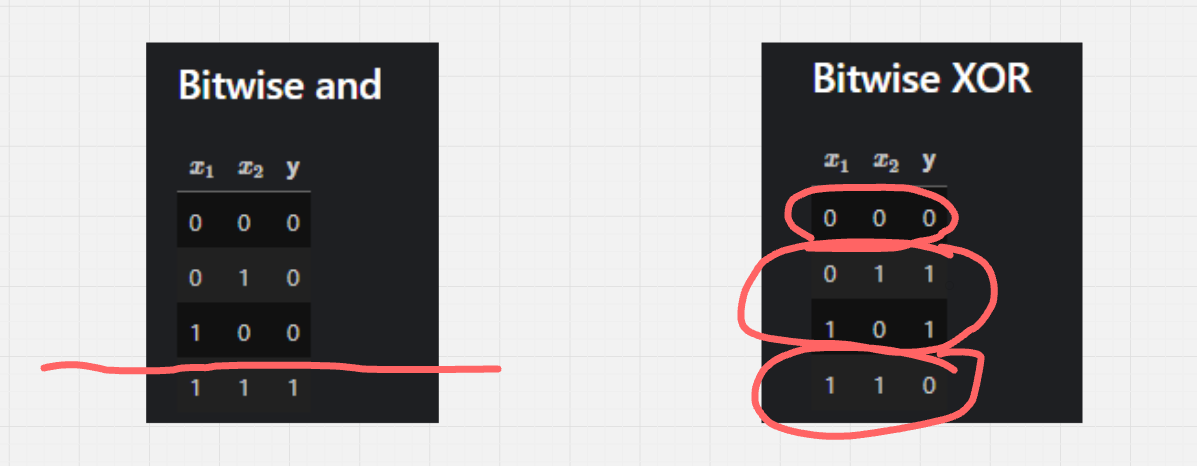